# LAB 1: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU BÁN LẺ SIÊU THỊ (ONLINE RETAIL)


In [7]:
pip install pandas numpy matplotlib seaborn scikit-learn sweetviz autoviz openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

## Đọc dữ liệu CSV


In [9]:
retail_df = pd.read_csv('../data/Online Retail.csv', encoding='latin1')

## Tiền xử lý dữ liệu


In [10]:
retail_df.dropna(subset=['CustomerID'], inplace=True)
retail_df = retail_df[retail_df['Quantity'] > 0]
retail_df['TotalPrice'] = retail_df['Quantity'] * retail_df['UnitPrice']

## Tính tổng doanh thu theo quốc gia

In [11]:
top_countries = retail_df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)

## Trực quan hóa

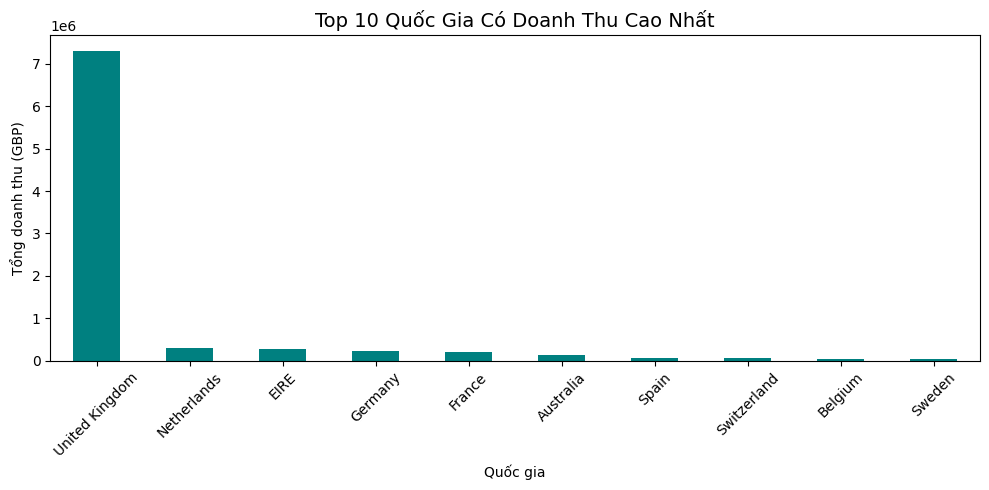

In [12]:
plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar', color='teal')
plt.title("Top 10 Quốc Gia Có Doanh Thu Cao Nhất", fontsize=14)
plt.xlabel("Quốc gia")
plt.ylabel("Tổng doanh thu (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/figures/retail_top_countries.png', dpi=300)
plt.show()


### GIẢI THÍCH Ý NGHĨA KẾT QUẢ CHẠY:
1. **Tiền xử lý:** Đã lọc bỏ các đơn hàng hoàn trả/hủy (`Quantity <= 0`) và các dòng thiếu thông tin khách hàng để đảm bảo doanh thu không bị sai lệch.
2. **Doanh thu thị trường:** Vương quốc Anh (United Kingdom) áp đảo hoàn toàn về doanh thu so với các quốc gia còn lại, do đây là thị trường nội địa chính của doanh nghiệp bán lẻ này.
